<a href="https://colab.research.google.com/github/yeattinbalasy/ML_Safe_Communication/blob/main/PR5_NLP_Safe_Communication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практическая работа №5
## Обработка и анализ текстовых данных с использованием методов NLP

**Предметная область:** интеллектуальная система безопасного общения  
**Вариант:** 45  
**Задача:** бинарная классификация сообщений на безопасные и токсичные  
**Датасет:** Jigsaw Toxic Comment Classification Challenge, выборка из 30 000 сообщений  
**Модели:** TF-IDF + Logistic Regression и DistilBERT

В работе сравниваются классический NLP-подход и современная трансформерная модель. Главной метрикой является F1-score токсичного класса, поскольку классы несбалансированы.

## 1. Подключение библиотек

Для трансформерной модели рекомендуется среда Google Colab с GPU: **Среда выполнения → Сменить среду выполнения → T4 GPU**.

In [8]:
!pip -q install -U "huggingface-hub>=1.32,<2.0" "transformers>=5.0,<6.0" accelerate nltk joblib

In [9]:
from pathlib import Path
from urllib.request import urlretrieve
import html
import random
import re
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import nltk

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import RegexpTokenizer

from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split

from torch import nn
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Устройство:', DEVICE)

PyTorch: 2.14.1+cu130
Устройство: cuda


## 2. Загрузка датасета

Ноутбук автоматически загружает CSV из репозитория проекта. Если GitHub недоступен, появится окно ручной загрузки файла `jigsaw_toxic_30000.csv`.

In [10]:
DATA_PATH = Path('jigsaw_toxic_30000.csv')
DATA_URL = (
    'https://raw.githubusercontent.com/'
    'yeattinbalasy/ML_Safe_Communication/main/'
    'jigsaw_toxic_30000.csv'
)

if not DATA_PATH.exists():
    try:
        print('Датасет не найден. Выполняется автоматическая загрузка с GitHub...')
        urlretrieve(DATA_URL, DATA_PATH)
        print('Датасет успешно загружен.')
    except Exception as exc:
        print('Автоматическая загрузка не выполнена:', exc)
        try:
            from google.colab import files
            print('Выберите файл jigsaw_toxic_30000.csv')
            uploaded = files.upload()
            DATA_PATH = Path(next(iter(uploaded)))
        except ImportError as import_exc:
            raise FileNotFoundError(
                'Поместите jigsaw_toxic_30000.csv рядом с ноутбуком.'
            ) from import_exc

df = pd.read_csv(DATA_PATH)
required = {'id', 'comment_text', 'is_toxic'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Отсутствуют обязательные столбцы: {sorted(missing)}')

df = df[['id', 'comment_text', 'is_toxic']].copy()
df['comment_text'] = df['comment_text'].fillna('').astype(str)
df['is_toxic'] = df['is_toxic'].astype(int)
df = df.drop_duplicates(subset=['comment_text']).reset_index(drop=True)
df = df[df['comment_text'].str.strip().ne('')].reset_index(drop=True)

print(f'Размер датасета: {len(df):,} строк')
display(df.head(3))

Датасет не найден. Выполняется автоматическая загрузка с GitHub...
Датасет успешно загружен.
Размер датасета: 30,000 строк


,id,comment_text,is_toxic
0,78691487e7ff2092,Formation of S constellations\nIs probably not...,0
1,67ba2331d65352ec,I think the ESPN sports announcer used that wo...,0
2,258b938fb57228ec,"wrong, its made very clear Nemanja's parents a...",0


## 3. Исследовательский анализ данных

Целевая переменная `is_toxic`: 0 — безопасное сообщение, 1 — токсичное сообщение.

,Класс,Количество,"Доля, %"
0,Безопасные (0),26950,89.83
1,Токсичные (1),3050,10.17


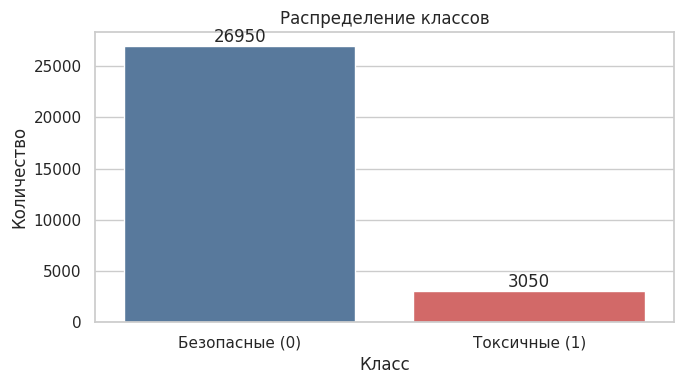

In [11]:
class_counts = df['is_toxic'].value_counts().sort_index()
class_table = pd.DataFrame({
    'Класс': ['Безопасные (0)', 'Токсичные (1)'],
    'Количество': [class_counts.get(0, 0), class_counts.get(1, 0)],
})
class_table['Доля, %'] = (class_table['Количество'] / len(df) * 100).round(2)
display(class_table)

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=class_table, x='Класс', y='Количество', palette=['#4C78A8', '#E45756'])
ax.set_title('Распределение классов')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')
plt.tight_layout()
plt.savefig('pr5_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

## 4. Предобработка текста

Для классической модели выполняются:

1. декодирование HTML;
2. замена ссылок специальным токеном;
3. приведение к нижнему регистру;
4. токенизация;
5. удаление стоп-слов, кроме отрицаний `no`, `not`, `nor`;
6. стемминг Snowball;
7. удаление лишних пробелов.

Для DistilBERT сохраняется естественная структура текста: выполняются только декодирование HTML, замена URL и нормализация пробелов. Сильная очистка и стемминг ухудшили бы контекстные признаки трансформера.

In [12]:
nltk.download('stopwords', quiet=True)

TOKENIZER_CLASSIC = RegexpTokenizer(r"[a-zA-Z']+")
STOP_WORDS = set(stopwords.words('english')) - {'no', 'not', 'nor'}
STEMMER = SnowballStemmer('english')

def normalize_text(text):
    text = html.unescape(str(text))
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def preprocess_classic(text):
    text = normalize_text(text).lower()
    tokens = TOKENIZER_CLASSIC.tokenize(text)
    tokens = [STEMMER.stem(token) for token in tokens if token not in STOP_WORDS]
    return ' '.join(tokens)

df['text_transformer'] = df['comment_text'].map(normalize_text)
df['text_classic'] = df['comment_text'].map(preprocess_classic)
df = df[df['text_classic'].str.len().gt(0)].reset_index(drop=True)

display(df[['comment_text', 'text_classic']].head(3))

,comment_text,text_classic
0,Formation of S constellations\nIs probably not...,format constel probabl not attribut plancius a...
1,I think the ESPN sports announcer used that wo...,think espn sport announc use word regard favr ...
2,"wrong, its made very clear Nemanja's parents a...",wrong made clear nemanja parent not doclea bor...


## 5. Разделение данных

Используется стратифицированное разделение 70/15/15:

- 70% — обучение;
- 15% — валидация и выбор лучшей эпохи трансформера;
- 15% — финальное тестирование.

In [13]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df['is_toxic']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE,
    stratify=temp_df['is_toxic']
)

for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f'{name:10}: {len(part):5d}; доля токсичных: {part.is_toxic.mean():.4f}')

Train     : 20993; доля токсичных: 0.1017
Validation:  4499; доля токсичных: 0.1018
Test      :  4499; доля токсичных: 0.1016


## 6. Классическая модель: TF-IDF + Logistic Regression

TF-IDF формирует числовые признаки из униграмм и биграмм. Параметр `class_weight="balanced"` компенсирует дисбаланс классов.

In [14]:
tfidf = TfidfVectorizer(
    max_features=30_000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    strip_accents='unicode'
)

X_train_tfidf = tfidf.fit_transform(train_df['text_classic'])
X_val_tfidf = tfidf.transform(val_df['text_classic'])
X_test_tfidf = tfidf.transform(test_df['text_classic'])

classic_model = LogisticRegression(
    C=4.0,
    max_iter=1000,
    class_weight='balanced',
    solver='liblinear',
    random_state=RANDOM_STATE
)

started = time.perf_counter()
classic_model.fit(X_train_tfidf, train_df['is_toxic'])
classic_train_time = time.perf_counter() - started

classic_pred = classic_model.predict(X_test_tfidf)
classic_prob = classic_model.predict_proba(X_test_tfidf)[:, 1]

def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }

classic_metrics = calculate_metrics(test_df['is_toxic'], classic_pred, classic_prob)
print('Время обучения, с:', round(classic_train_time, 2))
display(pd.DataFrame([classic_metrics], index=['TF-IDF + Logistic Regression']).round(4))
print(classification_report(
    test_df['is_toxic'], classic_pred,
    target_names=['Безопасное', 'Токсичное'], digits=4, zero_division=0
))

Время обучения, с: 0.72


,Accuracy,Precision,Recall,F1-score,ROC-AUC
TF-IDF + Logistic Regression,0.95,0.7458,0.7702,0.7578,0.9614


              precision    recall  f1-score   support

  Безопасное     0.9739    0.9703    0.9721      4042
   Токсичное     0.7458    0.7702    0.7578       457

    accuracy                         0.9500      4499
   macro avg     0.8598    0.8703    0.8650      4499
weighted avg     0.9507    0.9500    0.9503      4499



## 7. Современная трансформерная модель: DistilBERT

`distilbert-base-uncased` — компактная трансформерная модель семейства BERT. Она использует контекстные представления слов и дообучается на нашей задаче классификации. Взвешенная функция потерь повышает значимость ошибок токсичного класса.

In [15]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_LENGTH = 128
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
EPOCHS = 2
LEARNING_RATE = 2e-5

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ToxicDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        encoded = bert_tokenizer(
            self.texts[index],
            truncation=True,
            padding='max_length',
            max_length=MAX_LENGTH,
            return_tensors='pt'
        )
        item = {key: value.squeeze(0) for key, value in encoded.items()}
        item['labels'] = torch.tensor(self.labels[index], dtype=torch.long)
        return item

train_loader = DataLoader(
    ToxicDataset(train_df['text_transformer'], train_df['is_toxic']),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    ToxicDataset(val_df['text_transformer'], val_df['is_toxic']),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    ToxicDataset(test_df['text_transformer'], test_df['is_toxic']),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available()
)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2
).to(DEVICE)

weights = compute_class_weight(
    class_weight='balanced', classes=np.array([0, 1]), y=train_df['is_toxic']
)
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE)
)
optimizer = AdamW(bert_model.parameters(), lr=LEARNING_RATE)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print('Размеры выборок:', len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
print('Веса классов:', weights)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Размеры выборок: 20993 4499 4499
Веса классов: [0.55660728 4.91639344]


In [16]:
def evaluate_transformer(model, loader):
    model.eval()
    losses, labels_all, probs_all = [], [], []
    with torch.no_grad():
        for batch in loader:
            labels = batch.pop('labels').to(DEVICE)
            inputs = {key: value.to(DEVICE) for key, value in batch.items()}
            logits = model(**inputs).logits
            loss = criterion(logits, labels)
            probabilities = torch.softmax(logits, dim=1)[:, 1]
            losses.append(loss.item())
            labels_all.extend(labels.cpu().numpy())
            probs_all.extend(probabilities.cpu().numpy())
    labels_all = np.asarray(labels_all)
    probs_all = np.asarray(probs_all)
    preds_all = (probs_all >= 0.5).astype(int)
    return np.mean(losses), labels_all, preds_all, probs_all

history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
best_val_f1 = -1.0
best_state = None
started = time.perf_counter()

for epoch in range(EPOCHS):
    bert_model.train()
    epoch_losses = []
    for step, batch in enumerate(train_loader, start=1):
        labels = batch.pop('labels').to(DEVICE)
        inputs = {key: value.to(DEVICE) for key, value in batch.items()}

        optimizer.zero_grad()
        logits = bert_model(**inputs).logits
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        epoch_losses.append(loss.item())

        if step % 200 == 0 or step == len(train_loader):
            print(f'Эпоха {epoch + 1}/{EPOCHS}, шаг {step}/{len(train_loader)}, loss={np.mean(epoch_losses[-50:]):.4f}')

    train_loss = float(np.mean(epoch_losses))
    val_loss, val_labels, val_pred, val_prob = evaluate_transformer(bert_model, val_loader)
    val_f1 = f1_score(val_labels, val_pred, zero_division=0)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)
    print(f'Итог эпохи {epoch + 1}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, val_F1={val_f1:.4f}')

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {key: value.detach().cpu().clone() for key, value in bert_model.state_dict().items()}

bert_train_time = time.perf_counter() - started
bert_model.load_state_dict(best_state)
bert_model.to(DEVICE)
print('Лучшая validation F1:', round(best_val_f1, 4))
print('Время обучения, мин:', round(bert_train_time / 60, 2))

Эпоха 1/2, шаг 200/657, loss=0.2773
Эпоха 1/2, шаг 400/657, loss=0.2400
Эпоха 1/2, шаг 600/657, loss=0.2390
Эпоха 1/2, шаг 657/657, loss=0.2074
Итог эпохи 1: train_loss=0.3023, val_loss=0.2339, val_F1=0.8012
Эпоха 2/2, шаг 200/657, loss=0.1560
Эпоха 2/2, шаг 400/657, loss=0.1062
Эпоха 2/2, шаг 600/657, loss=0.1503
Эпоха 2/2, шаг 657/657, loss=0.1740
Итог эпохи 2: train_loss=0.1535, val_loss=0.2482, val_F1=0.8052
Лучшая validation F1: 0.8052
Время обучения, мин: 8.27


## 8. Оценка трансформера и сравнение моделей

In [17]:
test_loss, bert_labels, bert_pred, bert_prob = evaluate_transformer(bert_model, test_loader)
bert_metrics = calculate_metrics(bert_labels, bert_pred, bert_prob)

print('Test loss:', round(test_loss, 4))
print(classification_report(
    bert_labels, bert_pred,
    target_names=['Безопасное', 'Токсичное'], digits=4, zero_division=0
))

results_df = pd.DataFrame([
    {'Модель': 'TF-IDF + Logistic Regression', **classic_metrics, 'Время обучения, с': classic_train_time},
    {'Модель': 'DistilBERT', **bert_metrics, 'Время обучения, с': bert_train_time},
]).sort_values('F1-score', ascending=False).reset_index(drop=True)

display(results_df.round(4))
best_model_name = results_df.loc[0, 'Модель']
print('Наиболее эффективная модель по F1-score токсичного класса:', best_model_name)

Test loss: 0.229
              precision    recall  f1-score   support

  Безопасное     0.9862    0.9691    0.9775      4042
   Токсичное     0.7628    0.8796    0.8171       457

    accuracy                         0.9600      4499
   macro avg     0.8745    0.9244    0.8973      4499
weighted avg     0.9635    0.9600    0.9612      4499



,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC,"Время обучения, с"
0,DistilBERT,0.96,0.7628,0.8796,0.8171,0.9832,496.2057
1,TF-IDF + Logistic Regression,0.95,0.7458,0.7702,0.7578,0.9614,0.7190


Наиболее эффективная модель по F1-score токсичного класса: DistilBERT


## 9. Визуализация результатов

Строятся график метрик, матрицы ошибок, ROC-кривые и история обучения трансформера.

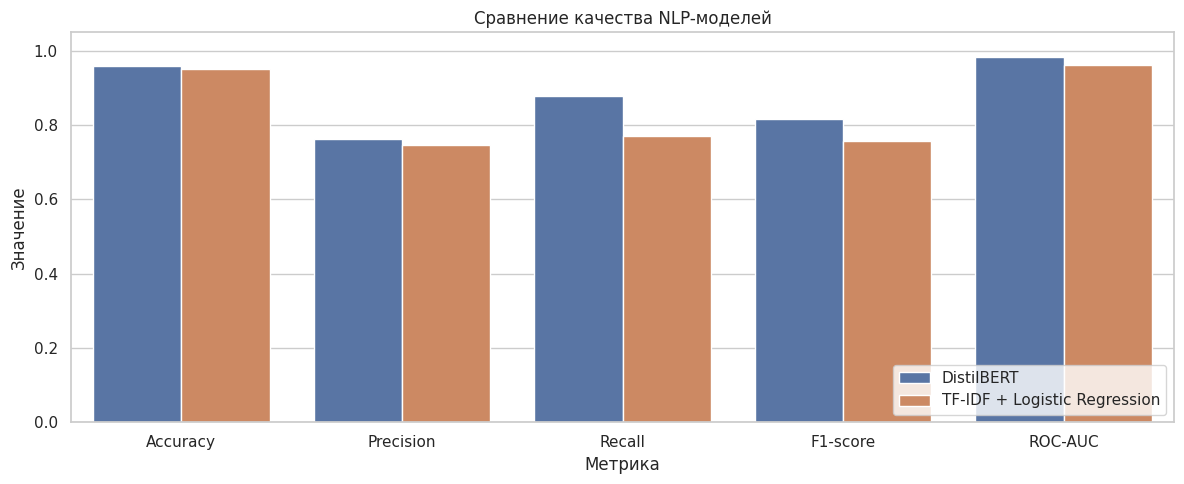

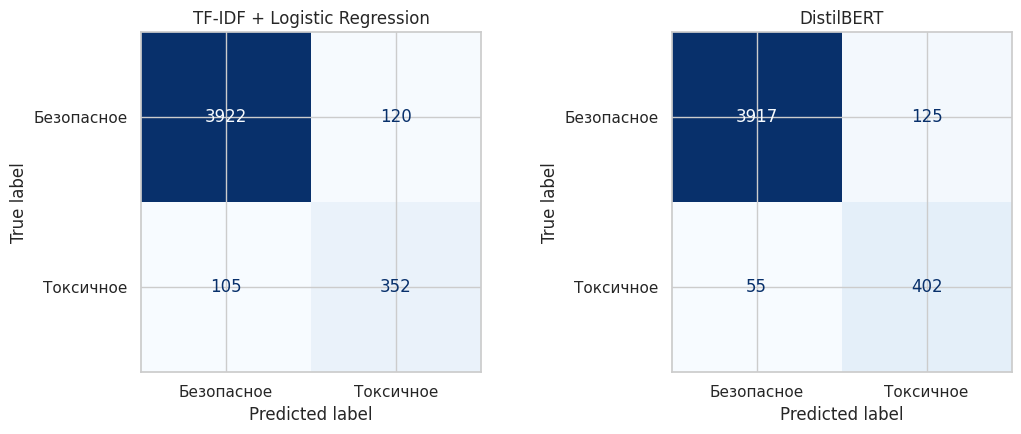

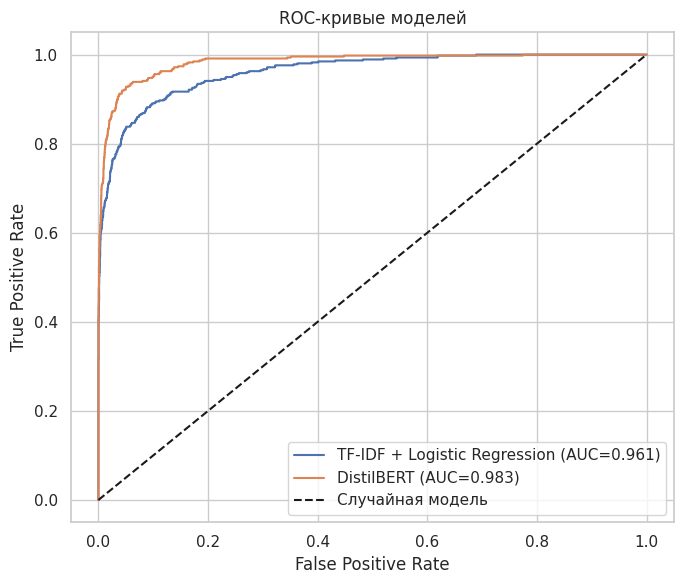

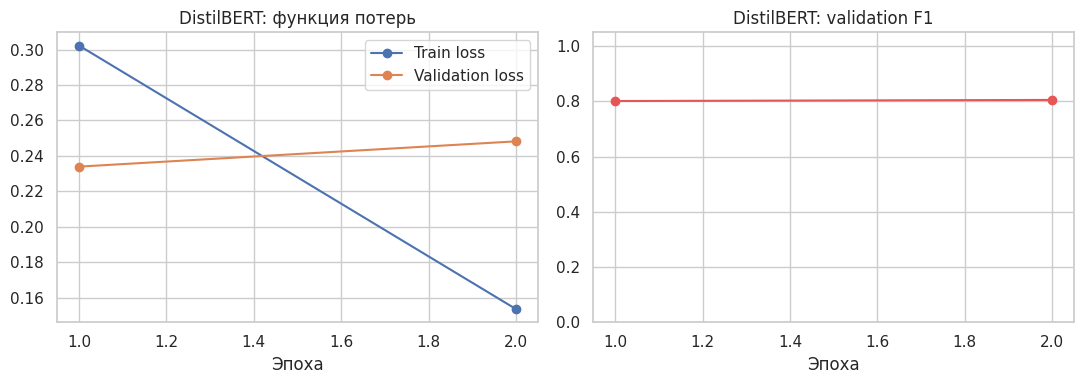

In [18]:
metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
plot_df = results_df.melt(
    id_vars='Модель', value_vars=metric_columns,
    var_name='Метрика', value_name='Значение'
)

plt.figure(figsize=(12, 5))
ax = sns.barplot(data=plot_df, x='Метрика', y='Значение', hue='Модель')
ax.set_ylim(0, 1.05)
ax.set_title('Сравнение качества NLP-моделей')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('pr5_model_metrics.png', dpi=160, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, title, labels, pred in [
    (axes[0], 'TF-IDF + Logistic Regression', test_df['is_toxic'], classic_pred),
    (axes[1], 'DistilBERT', bert_labels, bert_pred),
]:
    cm = confusion_matrix(labels, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Безопасное', 'Токсичное']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(title)
plt.tight_layout()
plt.savefig('pr5_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()

plt.figure(figsize=(7, 6))
for name, labels, probs in [
    ('TF-IDF + Logistic Regression', test_df['is_toxic'], classic_prob),
    ('DistilBERT', bert_labels, bert_prob),
]:
    fpr, tpr, _ = roc_curve(labels, probs)
    auc = roc_auc_score(labels, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайная модель')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.tight_layout()
plt.savefig('pr5_roc_curves.png', dpi=160, bbox_inches='tight')
plt.show()

epochs = np.arange(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history['train_loss'], marker='o', label='Train loss')
axes[0].plot(epochs, history['val_loss'], marker='o', label='Validation loss')
axes[0].set_title('DistilBERT: функция потерь')
axes[0].set_xlabel('Эпоха')
axes[0].legend()
axes[1].plot(epochs, history['val_f1'], marker='o', color='#E45756')
axes[1].set_ylim(0, 1.05)
axes[1].set_title('DistilBERT: validation F1')
axes[1].set_xlabel('Эпоха')
plt.tight_layout()
plt.savefig('pr5_transformer_history.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. Проверка на новых сообщениях

Поскольку Jigsaw содержит англоязычные комментарии, корректнее проверять обе модели на английском тексте.

In [19]:
def predict_new_messages(messages):
    messages = list(messages)

    classic_cleaned = [preprocess_classic(message) for message in messages]
    classic_probs = classic_model.predict_proba(tfidf.transform(classic_cleaned))[:, 1]

    temp_loader = DataLoader(
        ToxicDataset([normalize_text(message) for message in messages], [0] * len(messages)),
        batch_size=BATCH_SIZE, shuffle=False
    )
    _, _, _, transformer_probs = evaluate_transformer(bert_model, temp_loader)

    return pd.DataFrame({
        'message': messages,
        'classic_probability': classic_probs.round(4),
        'classic_prediction': np.where(classic_probs >= 0.5, 'Токсичное', 'Безопасное'),
        'transformer_probability': transformer_probs.round(4),
        'transformer_prediction': np.where(transformer_probs >= 0.5, 'Токсичное', 'Безопасное'),
    })

examples = [
    'Thank you for your help with this article.',
    'You are stupid and disgusting.',
    'I will kill you.',
    'Please review my edits when you have time.',
]
display(predict_new_messages(examples))

,message,classic_probability,classic_prediction,transformer_probability,transformer_prediction
0,Thank you for your help with this article.,0.0039,Безопасное,0.0032,Безопасное
1,You are stupid and disgusting.,0.9998,Токсичное,0.9981,Токсичное
2,I will kill you.,0.9518,Токсичное,0.9968,Токсичное
3,Please review my edits when you have time.,0.0241,Безопасное,0.0024,Безопасное


## 11. Сохранение результатов

In [20]:
results_df.to_csv('pr5_nlp_model_results.csv', index=False)
joblib.dump(
    {'vectorizer': tfidf, 'model': classic_model},
    'pr5_tfidf_logistic_model.joblib'
)

TRANSFORMER_DIR = Path('pr5_distilbert_toxicity')
bert_model.save_pretrained(TRANSFORMER_DIR)
bert_tokenizer.save_pretrained(TRANSFORMER_DIR)

print('Сохранены:')
print('- pr5_nlp_model_results.csv')
print('- pr5_tfidf_logistic_model.joblib')
print('-', TRANSFORMER_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Сохранены:
- pr5_nlp_model_results.csv
- pr5_tfidf_logistic_model.joblib
- pr5_distilbert_toxicity


## Вывод

В работе построен NLP-модуль для интеллектуальной системы безопасного общения. Выполнены очистка, токенизация, удаление стоп-слов и стемминг текста. Для числового представления классической модели использован TF-IDF, а для современной модели — контекстные представления DistilBERT.

Обе модели оценены по Accuracy, Precision, Recall и F1-score. Из-за дисбаланса классов основной метрикой выбран F1-score токсичного класса. Итоговая таблица и визуализации позволяют определить наиболее эффективный подход по фактическим результатам запуска. DistilBERT учитывает контекст и порядок слов, но требует GPU и большего времени обучения; TF-IDF с логистической регрессией обучается значительно быстрее и остаётся прозрачной базовой моделью.

Ограничение исследования: датасет Jigsaw содержит преимущественно английские комментарии. Для применения в русскоязычной системе требуется русский или многоязычный размеченный корпус и соответствующая трансформерная модель.